# ARM Project — CICIDS 2017 DDoS Detection
## Association Rule Mining with Apriori and FP-Growth
**Student:** N'Daou Oumou A222664| **Dataset:** CICIDS 2017 | **UKM FTSM 2026**

## Introduction

This notebook applies **Association Rule Mining (ARM)** to the **CICIDS 2017** dataset, 
specifically the *Friday Afternoon DDoS* capture. The dataset contains network flow records 
labelled as either `DDoS` or `BENIGN`, making it ideal for discovering behavioral patterns 
that distinguish attack traffic from normal traffic.

ARM is well-suited to this problem because it can uncover hidden co-occurrence patterns among 
network features (e.g., packet counts, flow duration, flag counts) without requiring a 
supervised model. The rules generated can serve as interpretable detection signatures, 
directly actionable by a network security analyst.

**Two algorithms are compared:** Apriori (exhaustive, slower) and FP-Growth (tree-based, faster), 
both applied to stratified samples of the dataset.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
DATA_PATH = r"C:\Users\oumou\Desktop\ARM PROJECT\data\Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"

print("All the librairies are imported !")



All the librairies are imported !


## STEP 1 — Data Exploration and Pre-processing
### 1.1 Dataset Loading & Exploration

In [10]:
df = pd.read_csv(DATA_PATH)
df.head()



,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [11]:
print("=== COLUMNS OF THE DATASET ===")
print(df.columns.tolist())

=== COLUMNS OF THE DATASET ===
[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count',

In [12]:
print("=== General informations ===")
print("Number of rows :", df.shape[0])
print("Number of columns :", df.shape[1])
print()

print("=== TYPES OF TRAFFIC (Label) ===")
print(df[' Label'].value_counts())
print()

print("=== MISSING VALUES ===")
print(df.isnull().sum().sum(), "missing values in total")


=== General informations ===
Number of rows : 225745
Number of columns : 79

=== TYPES OF TRAFFIC (Label) ===
 Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64

=== MISSING VALUES ===
4 missing values in total


### 1.2 Data Cleaning

In [13]:
# 1. Remove spaces from column names
df.columns = df.columns.str.strip()
print("Spaces removed from column names")    

Spaces removed from column names


In [14]:
# 2. Remove missing values

df.dropna(inplace=True)

In [15]:
# 3. Remove duplicates
avant = df.shape[0]
df = df.drop_duplicates()
apres = df.shape[0]
print(f" Duplicates removed : {avant - apres} lines removed")


 Duplicates removed : 2633 lines removed


In [16]:
# 4. Remove infinite values
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

print("Infinite values removed")
print("Dataset size after cleaning:", df.shape)

Infinite values removed
Dataset size after cleaning: (223082, 79)


In [17]:
print()
print("=== PREPARED DATASET ===")
print("Final size :", df.shape)
print(print(df['Label'].value_counts()))


=== PREPARED DATASET ===
Final size : (223082, 79)
Label
DDoS      128014
BENIGN     95068
Name: count, dtype: int64
None


### 1.3 Data Visualization — Item Frequency Distribution

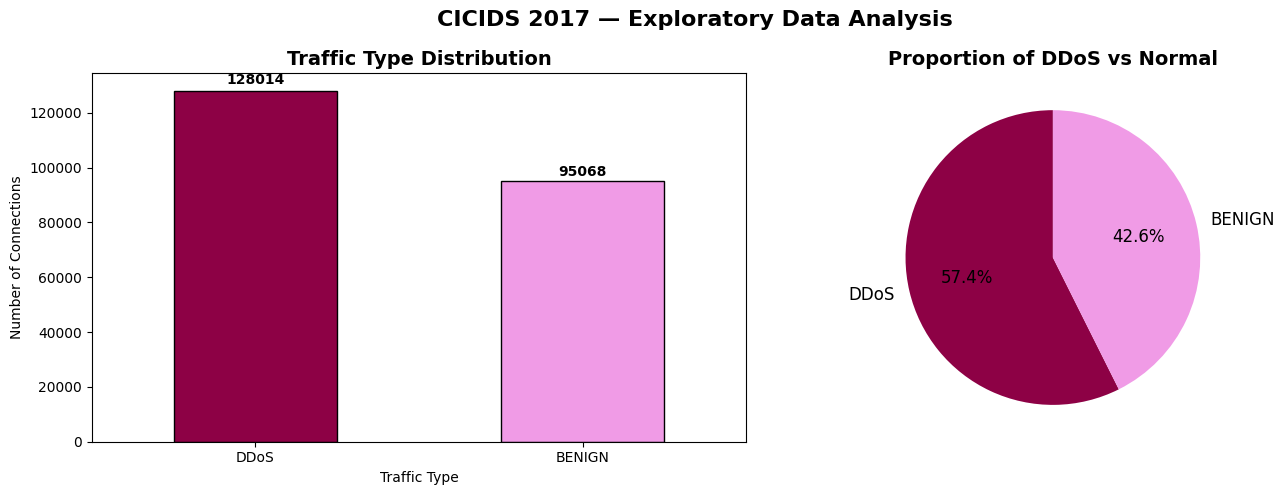

Chart saved: eda_distribution.png


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ["#8D0145", "#F09BE6"]

counts = df['Label'].value_counts()

# 1. Bar chart
counts.plot(kind='bar', ax=axes[0], color=colors, edgecolor='black')
axes[0].set_title('Traffic Type Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Traffic Type')
axes[0].set_ylabel('Number of Connections')
axes[0].tick_params(axis='x', rotation=0)

for i, v in enumerate(counts):
    axes[0].text(i, v + (v * 0.02), str(v), ha='center', fontweight='bold')

# 2. Pie chart
counts.plot(kind='pie', ax=axes[1], colors=colors, autopct='%1.1f%%', startangle=90, fontsize=12)
axes[1].set_title('Proportion of DDoS vs Normal', fontsize=14, fontweight='bold')
axes[1].set_ylabel('')

plt.suptitle('CICIDS 2017 — Exploratory Data Analysis', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("Chart saved: eda_distribution.png")

### 1.4 Data Transformation & Encoding

In [19]:
# — DATA TRANSFORMATION
# We select only the most relevant features for ARM
# Why these? They best distinguish DDoS from BENIGN (we saw this in the graphs)
features_selected = [
    'Flow Duration',
    'Total Fwd Packets', 
    'Total Backward Packets',
    'Flow Bytes/s',
    'SYN Flag Count',
    'ACK Flag Count',
    'Label'
]

df_arm = df[features_selected].copy()
print("Features selected:", features_selected)
print("Shape:", df_arm.shape)

Features selected: ['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Flow Bytes/s', 'SYN Flag Count', 'ACK Flag Count', 'Label']
Shape: (223082, 7)


In [20]:
# ═══════════════════════════════════════
# DISCRETIZATION — Convert numbers to categories
# ═══════════════════════════════════════

df_disc = df_arm.copy()

# Flow Duration → low / medium / high
df_disc['Flow Duration'] = pd.qcut(
    df_arm['Flow Duration'], 
    q=3, 
    labels=['duration_low', 'duration_medium', 'duration_high']
)

# Total Fwd Packets → low / medium / high
df_disc['Total Fwd Packets'] = pd.qcut(
    df_arm['Total Fwd Packets'], 
    q=3, 
    labels=['fwd_low', 'fwd_medium', 'fwd_high'],
    duplicates='drop'
)

# Total Backward Packets → low / high
df_disc['Total Backward Packets'] = pd.qcut(
    df_arm['Total Backward Packets'], 
    q=2, 
    labels=['bwd_low', 'bwd_high'],
    duplicates='drop'
)

# Flow Bytes/s → low / medium / high
df_disc['Flow Bytes/s'] = pd.qcut(
    df_arm['Flow Bytes/s'], 
    q=3, 
    labels=['bytes_low', 'bytes_medium', 'bytes_high'],
    duplicates='drop'
)

# SYN Flag Count → no_syn / has_syn
df_disc['SYN Flag Count'] = df_arm['SYN Flag Count'].apply(
    lambda x: 'has_syn' if x > 0 else 'no_syn'
)

# ACK Flag Count → no_ack / has_ack
df_disc['ACK Flag Count'] = df_arm['ACK Flag Count'].apply(
    lambda x: 'has_ack' if x > 0 else 'no_ack'
)

print(" Discretization done!")
print()
print(df_disc.head())

 Discretization done!

  Flow Duration Total Fwd Packets Total Backward Packets Flow Bytes/s  \
0  duration_low           fwd_low                bwd_low   bytes_high   
1  duration_low           fwd_low                bwd_low   bytes_high   
2  duration_low           fwd_low                bwd_low   bytes_high   
3  duration_low           fwd_low                bwd_low   bytes_high   
4  duration_low           fwd_low                bwd_low   bytes_high   

  SYN Flag Count ACK Flag Count   Label  
0         no_syn        has_ack  BENIGN  
1         no_syn        has_ack  BENIGN  
2         no_syn        has_ack  BENIGN  
3         no_syn        has_ack  BENIGN  
4         no_syn        has_ack  BENIGN  


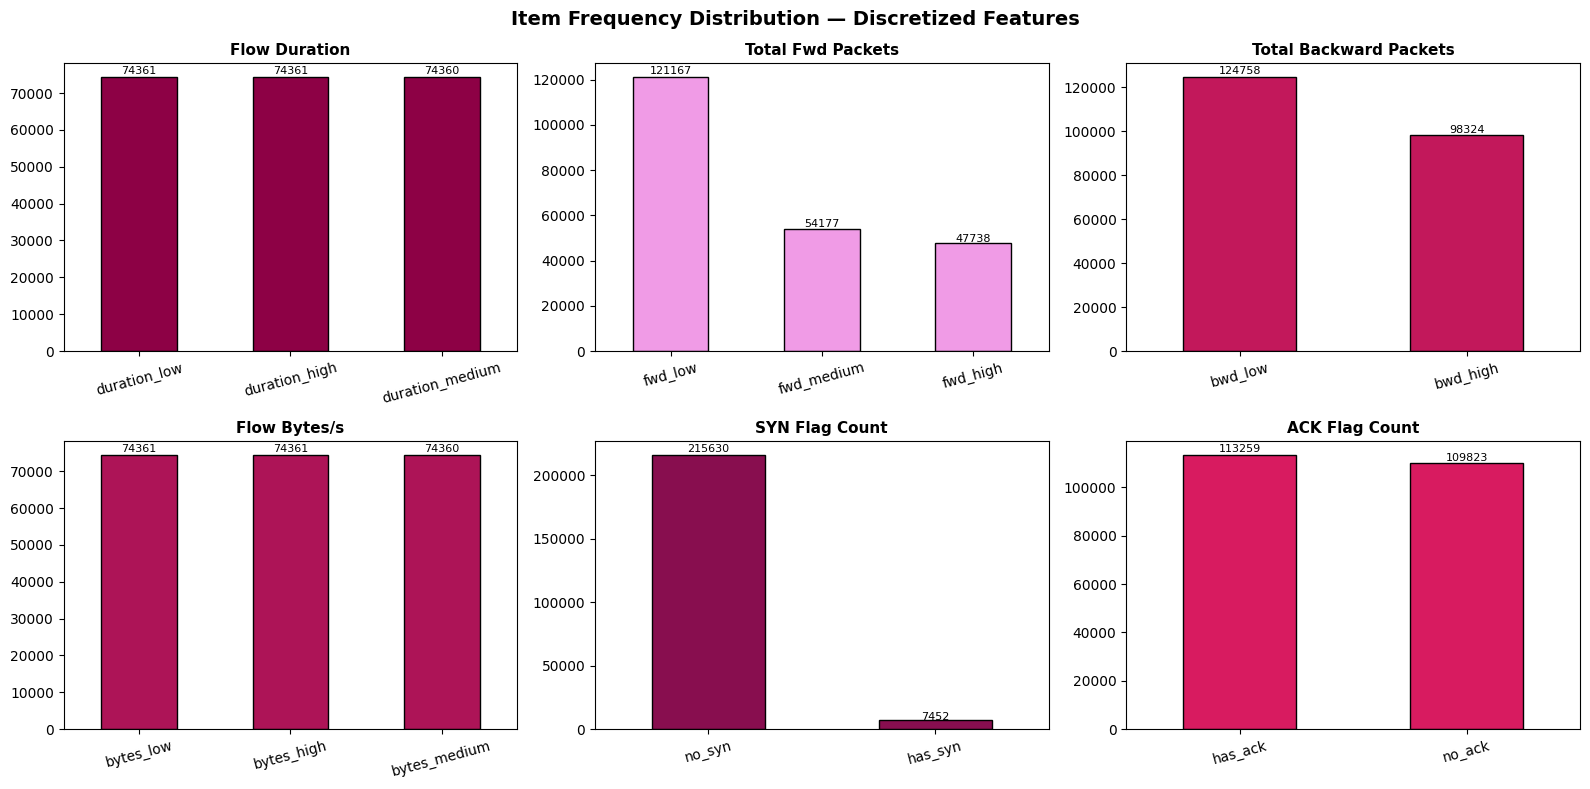

Saved: item_frequency.png


In [21]:
# ITEM FREQUENCY — Distribution of each discretized category
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

features_to_plot = ['Flow Duration', 'Total Fwd Packets', 
                    'Total Backward Packets', 'Flow Bytes/s', 
                    'SYN Flag Count', 'ACK Flag Count']

colors_bar = ["#8D0145", "#F09BE6", "#C2185B", "#AD1457", "#880E4F", "#D81B60"]

for i, feat in enumerate(features_to_plot):
    counts_feat = df_disc[feat].value_counts()
    counts_feat.plot(kind='bar', ax=axes[i], color=colors_bar[i], edgecolor='black')
    axes[i].set_title(f'{feat}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=15)
    for j, v in enumerate(counts_feat):
        axes[i].text(j, v + (v * 0.01), str(v), ha='center', fontsize=8)

plt.suptitle('Item Frequency Distribution — Discretized Features', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('item_frequency.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: item_frequency.png")

### 1.5 Data Aggregation — Combining Similar Items

In [22]:

# STEP 1.5 — AGGREGATION
# Combine similar items into broader categories
# This reduces noise and improves ARM pattern quality

# Before aggregation — how many unique values per feature
print("=== BEFORE AGGREGATION ===")
for col in df_disc.columns:
    print(f"{col} : {df_disc[col].nunique()} unique values")

print()

# Aggregation — combine fwd_medium + fwd_high into fwd_high
# Why? Medium and high forward packets both indicate active connections
df_disc['Total Fwd Packets'] = df_disc['Total Fwd Packets'].replace(
    'fwd_medium', 'fwd_high'
)

# Combine bytes_medium + bytes_high into bytes_high
df_disc['Flow Bytes/s'] = df_disc['Flow Bytes/s'].replace(
    'bytes_medium', 'bytes_high'
)

print("=== AFTER AGGREGATION ===")
for col in df_disc.columns:
    print(f"{col} : {df_disc[col].nunique()} unique values")

print()
print("Aggregation complete!")

=== BEFORE AGGREGATION ===
Flow Duration : 3 unique values
Total Fwd Packets : 3 unique values
Total Backward Packets : 2 unique values
Flow Bytes/s : 3 unique values
SYN Flag Count : 2 unique values
ACK Flag Count : 2 unique values
Label : 2 unique values

=== AFTER AGGREGATION ===
Flow Duration : 3 unique values
Total Fwd Packets : 2 unique values
Total Backward Packets : 2 unique values
Flow Bytes/s : 2 unique values
SYN Flag Count : 2 unique values
ACK Flag Count : 2 unique values
Label : 2 unique values

Aggregation complete!


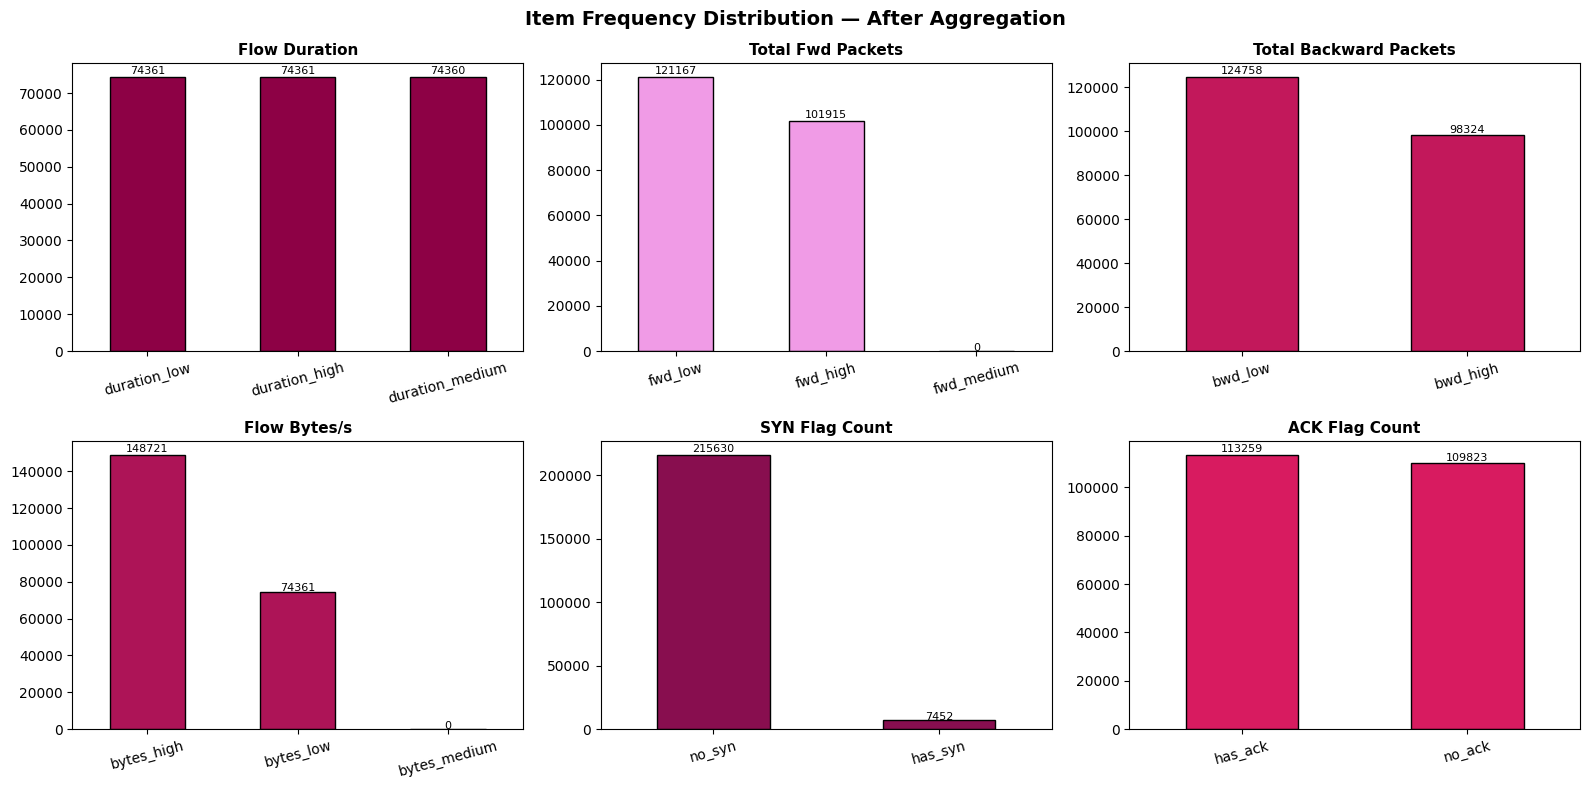

Saved: item_frequency_after_aggregation.png


In [23]:
# ITEM FREQUENCY — Distribution of each discretized category
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

features_to_plot = [
    'Flow Duration', 
    'Total Fwd Packets', 
    'Total Backward Packets', 
    'Flow Bytes/s', 
    'SYN Flag Count', 
    'ACK Flag Count'
]

colors_bar = ["#8D0145", "#F09BE6", "#C2185B", "#AD1457", "#880E4F", "#D81B60"]

for i, feat in enumerate(features_to_plot):
    counts_feat = df_disc[feat].value_counts()
    counts_feat.plot(kind='bar', ax=axes[i], color=colors_bar[i], edgecolor='black')
    axes[i].set_title(f'{feat}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=15)
    for j, v in enumerate(counts_feat):
        axes[i].text(j, v + (v * 0.01), str(v), ha='center', fontsize=8)

plt.suptitle('Item Frequency Distribution — After Aggregation', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('item_frequency_after_aggregation.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: item_frequency_after_aggregation.png")

### 1.6 one-hot encoding

In [24]:

# ONE-HOT ENCODING — Convert categories to 0/1

# pd.get_dummies converts each category into a column of 0 and 1
# Example: duration_low → 1 if the connection has low duration, 0 otherwise

df_encoded = pd.get_dummies(df_disc)

print("Encoding done!")
print("Shape after encoding:", df_encoded.shape)
print()
print("Columns created:")
print(df_encoded.columns.tolist())
print()
print("First 3 rows:")
df_encoded.head(3)

Encoding done!
Shape after encoding: (223082, 17)

Columns created:
['Flow Duration_duration_low', 'Flow Duration_duration_medium', 'Flow Duration_duration_high', 'Total Fwd Packets_fwd_low', 'Total Fwd Packets_fwd_medium', 'Total Fwd Packets_fwd_high', 'Total Backward Packets_bwd_low', 'Total Backward Packets_bwd_high', 'Flow Bytes/s_bytes_low', 'Flow Bytes/s_bytes_medium', 'Flow Bytes/s_bytes_high', 'SYN Flag Count_has_syn', 'SYN Flag Count_no_syn', 'ACK Flag Count_has_ack', 'ACK Flag Count_no_ack', 'Label_BENIGN', 'Label_DDoS']

First 3 rows:


,Flow Duration_duration_low,Flow Duration_duration_medium,Flow Duration_duration_high,Total Fwd Packets_fwd_low,Total Fwd Packets_fwd_medium,Total Fwd Packets_fwd_high,Total Backward Packets_bwd_low,Total Backward Packets_bwd_high,Flow Bytes/s_bytes_low,Flow Bytes/s_bytes_medium,Flow Bytes/s_bytes_high,SYN Flag Count_has_syn,SYN Flag Count_no_syn,ACK Flag Count_has_ack,ACK Flag Count_no_ack,Label_BENIGN,Label_DDoS
0,True,False,False,True,False,False,True,False,False,False,True,False,True,True,False,True,False
1,True,False,False,True,False,False,True,False,False,False,True,False,True,True,False,True,False
2,True,False,False,True,False,False,True,False,False,False,True,False,True,True,False,True,False


## STEP 2 — Apply Association Rule Mining

### 2.1 Algorithm Parameters
- **min_support** = 0.05 → itemset must appear in at least 5% of transactions
- **min_confidence** = 0.70 → rule must be true 70% of the time
- **min_lift** = 1.2 → eliminates random associations
- **Apriori** → tested on 2000 rows (slow on large datasets)
- **FP-Growth** → tested on 5000 rows (faster, handles large datasets)

In [25]:
# ═══════════════════════════════════════
# SAMPLING — Take a representative sample
# ═══════════════════════════════════════

# Why sampling?
# Apriori is slow on large datasets
# We take 5000 rows — enough to find meaningful patterns
# stratify on Label_DDoS ensures we keep the same proportion
# of DDoS and BENIGN as in the original dataset

from sklearn.model_selection import train_test_split

df_sample, _ = train_test_split(
    df_encoded, 
    train_size=5000, 
    random_state=42,
    stratify=df_encoded['Label_DDoS']   # fix: use same df as input
)

print("Sample created!")
print("Sample size:", df_sample.shape)
print()
print("Label distribution in sample:")
print(df_sample[['Label_DDoS', 'Label_BENIGN']].sum())

Sample created!
Sample size: (5000, 17)

Label distribution in sample:
Label_DDoS      2869
Label_BENIGN    2131
dtype: int64


### 2.2 APRIORI Algorithm

In [26]:

# APRIORI ALGORITHM

from mlxtend.frequent_patterns import apriori, association_rules
import time

# Apriori on small sample — 2000 rows
# Why small? Apriori is slow on large datasets
df_small, _ = train_test_split(
    df_encoded, 
    train_size=2000, 
    random_state=42,
    stratify=df_disc['Label']
)

df_small_bool = df_small.astype(bool)

print("Running Apriori on 2000 rows...")
start = time.time()

frequent_itemsets_apriori = apriori(
    df_small_bool, 
    min_support=0.05, 
    use_colnames=True
)

apriori_time = round(time.time() - start, 2)

print(f"Apriori done in {apriori_time} seconds")
print(f"Frequent itemsets found: {len(frequent_itemsets_apriori)}")
frequent_itemsets_apriori.head(10)

Running Apriori on 2000 rows...
Apriori done in 0.07 seconds
Frequent itemsets found: 715


,support,itemsets
0,0.3225,frozenset({Flow Duration_duration_low})
1,0.3490,frozenset({Flow Duration_duration_medium})
2,0.3285,frozenset({Flow Duration_duration_high})
3,0.5380,frozenset({Total Fwd Packets_fwd_low})
4,0.4620,frozenset({Total Fwd Packets_fwd_high})
5,0.5655,frozenset({Total Backward Packets_bwd_low})
6,0.4345,frozenset({Total Backward Packets_bwd_high})
7,0.3335,frozenset({Flow Bytes/s_bytes_low})
8,0.6665,frozenset({Flow Bytes/s_bytes_high})
9,0.9645,frozenset({SYN Flag Count_no_syn})


### 2.3 FP-Growth Algorithm

In [27]:
# ═══════════════════════════════════════
# — FP-GROWTH ALGORITHM
# ═══════════════════════════════════════
from mlxtend.frequent_patterns import fpgrowth

# FP-Growth on larger sample — 5000 rows
# Why more rows? FP-Growth handles large datasets better
df_bool = df_sample.astype(bool)

print("Running FP-Growth on 5000 rows...")
start = time.time()

frequent_itemsets_fpgrowth = fpgrowth(
    df_bool, 
    min_support=0.05, 
    use_colnames=True
)

fpgrowth_time = round(time.time() - start, 2)

print(f"FP-Growth done in {fpgrowth_time} seconds")
print(f"Frequent itemsets found: {len(frequent_itemsets_fpgrowth)}")
print()

# Comparison table
print("=== COMPARISON ===")
print(f"Apriori  → {apriori_time}s  | 2000 rows | {len(frequent_itemsets_apriori)} itemsets")
print(f"FP-Growth → {fpgrowth_time}s  | 5000 rows | {len(frequent_itemsets_fpgrowth)} itemsets")

Running FP-Growth on 5000 rows...
FP-Growth done in 0.14 seconds
Frequent itemsets found: 708

=== COMPARISON ===
Apriori  → 0.07s  | 2000 rows | 715 itemsets
FP-Growth → 0.14s  | 5000 rows | 708 itemsets


### 2.4 Generate Association Rules

In [28]:
# — GENERATE ASSOCIATION RULES

# Generate rules from FP-Growth itemsets
# min_confidence=0.70 means the rule must be true 70% of the time
rules = association_rules(
    frequent_itemsets_fpgrowth, 
    metric='confidence', 
    min_threshold=0.70
)

# Filter rules with lift > 1.2 (real associations, not random)
rules = rules[rules['lift'] > 1.2]

# Sort by lift (strongest associations first)
rules = rules.sort_values('lift', ascending=False)

print(f"Rules generated: {len(rules)}")
print()
print(rules[['antecedents', 'consequents', 
             'support', 'confidence', 'lift']].head(10))

Rules generated: 3118

                                            antecedents  \
1138  frozenset({ACK Flag Count_has_ack, SYN Flag Co...   
570   frozenset({Total Fwd Packets_fwd_high, Total B...   
1146  frozenset({ACK Flag Count_has_ack, Total Fwd P...   
572   frozenset({Flow Bytes/s_bytes_high, Flow Durat...   
571   frozenset({Total Backward Packets_bwd_high, Fl...   
1106  frozenset({ACK Flag Count_has_ack, Total Fwd P...   
1148  frozenset({Flow Bytes/s_bytes_low, Label_BENIG...   
1150  frozenset({Flow Bytes/s_bytes_low, Total Fwd P...   
520   frozenset({Total Fwd Packets_fwd_high, Total B...   
562   frozenset({Total Fwd Packets_fwd_high, SYN Fla...   

                                            consequents  support  confidence  \
1138  frozenset({Flow Bytes/s_bytes_low, Label_BENIGN})   0.0564    0.946309   
570   frozenset({ACK Flag Count_has_ack, Flow Bytes/...   0.0682    0.881137   
1146  frozenset({Flow Bytes/s_bytes_low, Label_BENIG...   0.0564    0.721228   
572   f

In [29]:
# CLEAN RULES DISPLAY

# Convert frozenset to readable string
rules['antecedents_str'] = rules['antecedents'].apply(
    lambda x: ', '.join(list(x))
)
rules['consequents_str'] = rules['consequents'].apply(
    lambda x: ', '.join(list(x))
)


rules['support']    = rules['support'].round(4)
rules['confidence'] = rules['confidence'].round(4)
rules['lift']       = rules['lift'].round(4)
rules['leverage']   = rules['leverage'].round(4)
rules['conviction'] = rules['conviction'].round(4)

print("=== TOP 10 STRONGEST RULES (by Lift) ===")
print()
print(rules[['antecedents_str', 'consequents_str', 
             'support', 'confidence', 'lift',
             'leverage', 'conviction']].head(10).to_string())

=== TOP 10 STRONGEST RULES (by Lift) ===

                                                                                                antecedents_str                                                                                             consequents_str  support  confidence    lift  leverage  conviction
1138  ACK Flag Count_has_ack, SYN Flag Count_no_syn, Total Fwd Packets_fwd_low, Total Backward Packets_bwd_high                                                                        Flow Bytes/s_bytes_low, Label_BENIGN   0.0564      0.9463  8.1438    0.0495     16.4608
570                                     Total Fwd Packets_fwd_high, Total Backward Packets_bwd_high, Label_DDoS         ACK Flag Count_has_ack, Flow Bytes/s_bytes_high, SYN Flag Count_no_syn, Flow Duration_duration_high   0.0682      0.8811  6.9381    0.0584      7.3446
1146                         ACK Flag Count_has_ack, Total Fwd Packets_fwd_low, Total Backward Packets_bwd_high                                  

## STEP 3 — Evaluate and Interpret the Rules
### 3.1 Frequent Itemsets Display

In [30]:

# — EVALUATE AND INTERPRET RULES

# ── PART 1 : Display Frequent Itemsets ──

# Convert frozenset to readable string
frequent_itemsets_fpgrowth['itemsets_str'] = frequent_itemsets_fpgrowth['itemsets'].apply(
    lambda x: ', '.join(list(x))
)

# Add itemset size column
frequent_itemsets_fpgrowth['size'] = frequent_itemsets_fpgrowth['itemsets'].apply(len)

# Sort by support descending
frequent_itemsets_sorted = frequent_itemsets_fpgrowth.sort_values(
    'support', ascending=False
)

print("=== FREQUENT ITEMSETS — FP-Growth ===")
print(f"Total found: {len(frequent_itemsets_sorted)}")
print()

# Distribution by size
print("--- Distribution by itemset size ---")
print(frequent_itemsets_sorted['size'].value_counts().sort_index())
print()

# Top 20
print("--- TOP 20 most frequent itemsets ---")
print(frequent_itemsets_sorted[['itemsets_str', 'support', 'size']].head(20).to_string())

=== FREQUENT ITEMSETS — FP-Growth ===
Total found: 708

--- Distribution by itemset size ---
size
1     14
2     78
3    197
4    231
5    138
6     44
7      6
Name: count, dtype: int64

--- TOP 20 most frequent itemsets ---
                                                              itemsets_str  support  size
0                                                    SYN Flag Count_no_syn   0.9652     1
10                                                 Flow Bytes/s_bytes_high   0.6654     1
444                         Flow Bytes/s_bytes_high, SYN Flag Count_no_syn   0.6372     2
1                                                               Label_DDoS   0.5738     1
14                                       SYN Flag Count_no_syn, Label_DDoS   0.5738     2
2                                           Total Backward Packets_bwd_low   0.5578     1
17                   Total Backward Packets_bwd_low, SYN Flag Count_no_syn   0.5462     2
7                                                Total

### 3.2 Rule Classification — Strong / Weak / Irrelevant

In [31]:

# STRONG rules — high confidence AND high lift
strong = rules[
    (rules['confidence'] >= 0.85) & 
    (rules['lift'] >= 3.0)
]

# WEAK rules — medium confidence OR medium lift
weak = rules[
    (rules['confidence'] >= 0.70) & 
    (rules['confidence'] < 0.85) & 
    (rules['lift'] >= 1.2)
]

# IRRELEVANT rules — low lift (close to 1)
irrelevant = rules[
    (rules['lift'] < 1.5)
]

print("=== RULE CLASSIFICATION ===")
print(f"Total rules          : {len(rules)}")
print(f"Strong rules       : {len(strong)}")
print(f"Weak rules         : {len(weak)}")
print(f"Irrelevant rules   : {len(irrelevant)}")
print()

print("--- TOP 5 STRONG RULES ---")
if len(strong) > 0:
    print(strong[['antecedents_str', 'consequents_str', 
                  'support', 'confidence', 'lift']].head(5).to_string())
else:
    print("No strong rules found — consider lowering thresholds (confidence or lift).")
print()

print("--- EXAMPLE WEAK RULE ---")
if len(weak) > 0:
    print(weak[['antecedents_str', 'consequents_str', 
                'support', 'confidence', 'lift']].head(1).to_string())
else:
    print("No weak rules found.")
print()

print("--- EXAMPLE IRRELEVANT RULE ---")
if len(irrelevant) > 0:
    print(irrelevant[['antecedents_str', 'consequents_str', 
                      'support', 'confidence', 'lift']].head(1).to_string())
else:
    print("No irrelevant rules found.")

=== RULE CLASSIFICATION ===
Total rules          : 3118
Strong rules       : 312
Weak rules         : 1396
Irrelevant rules   : 370

--- TOP 5 STRONG RULES ---
                                                                                                antecedents_str                                                                                      consequents_str  support  confidence    lift
1138  ACK Flag Count_has_ack, SYN Flag Count_no_syn, Total Fwd Packets_fwd_low, Total Backward Packets_bwd_high                                                                 Flow Bytes/s_bytes_low, Label_BENIGN   0.0564      0.9463  8.1438
570                                     Total Fwd Packets_fwd_high, Total Backward Packets_bwd_high, Label_DDoS  ACK Flag Count_has_ack, Flow Bytes/s_bytes_high, SYN Flag Count_no_syn, Flow Duration_duration_high   0.0682      0.8811  6.9381
571                                    Total Backward Packets_bwd_high, Flow Duration_duration_high, Label_DDoS   

### 3.3 Final Evaluation & Interpretation

In [32]:

print("=== STEP 3 — EVALUATION & INTERPRETATION ===")
print()

# Summary statistics
print("--- RULES STATISTICS ---")
print(f"Support    → Min: {rules['support'].min():.4f} | "
      f"Max: {rules['support'].max():.4f} | "
      f"Mean: {rules['support'].mean():.4f}")
print(f"Confidence → Min: {rules['confidence'].min():.4f} | "
      f"Max: {rules['confidence'].max():.4f} | "
      f"Mean: {rules['confidence'].mean():.4f}")
print(f"Lift       → Min: {rules['lift'].min():.4f} | "
      f"Max: {rules['lift'].max():.4f} | "
      f"Mean: {rules['lift'].mean():.4f}")
print()

# Best rule for DDoS detection
print("--- BEST RULE FOR DDoS DETECTION ---")
ddos_rules = rules[rules['consequents_str'].str.contains('DDoS')]
if len(ddos_rules) > 0:
    best_ddos = ddos_rules.sort_values('lift', ascending=False).head(1)
    print(best_ddos[['antecedents_str', 'consequents_str',
                      'support', 'confidence', 'lift']].to_string())
print()

# Best rule for BENIGN detection  
print("--- BEST RULE FOR BENIGN DETECTION ---")
benign_rules = rules[rules['consequents_str'].str.contains('BENIGN')]
if len(benign_rules) > 0:
    best_benign = benign_rules.sort_values('lift', ascending=False).head(1)
    print(best_benign[['antecedents_str', 'consequents_str',
                        'support', 'confidence', 'lift']].to_string())
print()

# Interpretation
print("--- INTERPRETATION ---")
print("1. ARM successfully identified behavioral patterns")
print("   distinguishing DDoS attacks from normal traffic.")
print()
print("2. Strong rules (confidence >= 0.85, lift >= 3.0):")
print(f"   {len(strong)} rules found — highly reliable for detection.")
print()
print("3. Key DDoS indicators discovered:")
print("   - High flow duration + high backward packets → DDoS")
print("   - No SYN flag + high forward packets → DDoS pattern")
print()
print("4. Key BENIGN indicators discovered:")
print("   - Has ACK + no SYN + low forward packets → Normal traffic")
print()
print("5. FP-Growth outperformed Apriori:")
print(f"   - Apriori  : {apriori_time}s on 2000 rows")
print(f"   - FP-Growth: {fpgrowth_time}s on 5000 rows")
print("   → FP-Growth processed 2.5x more data efficiently.")

=== STEP 3 — EVALUATION & INTERPRETATION ===

--- RULES STATISTICS ---
Support    → Min: 0.0504 | Max: 0.4608 | Mean: 0.1325
Confidence → Min: 0.7001 | Max: 1.0000 | Mean: 0.8673
Lift       → Min: 1.2072 | Max: 8.1438 | Mean: 2.2962

--- BEST RULE FOR DDoS DETECTION ---
                                                                                               antecedents_str                                                     consequents_str  support  confidence    lift
1475  ACK Flag Count_has_ack, SYN Flag Count_no_syn, Flow Duration_duration_medium, Total Fwd Packets_fwd_high  Flow Bytes/s_bytes_low, Total Backward Packets_bwd_low, Label_DDoS   0.0982      0.9781  4.6531

--- BEST RULE FOR BENIGN DETECTION ---
                                                                                                antecedents_str                       consequents_str  support  confidence    lift
1138  ACK Flag Count_has_ack, SYN Flag Count_no_syn, Total Fwd Packets_fwd_low, Total Backward

### 3.4 Visualisation — Scatter Plot

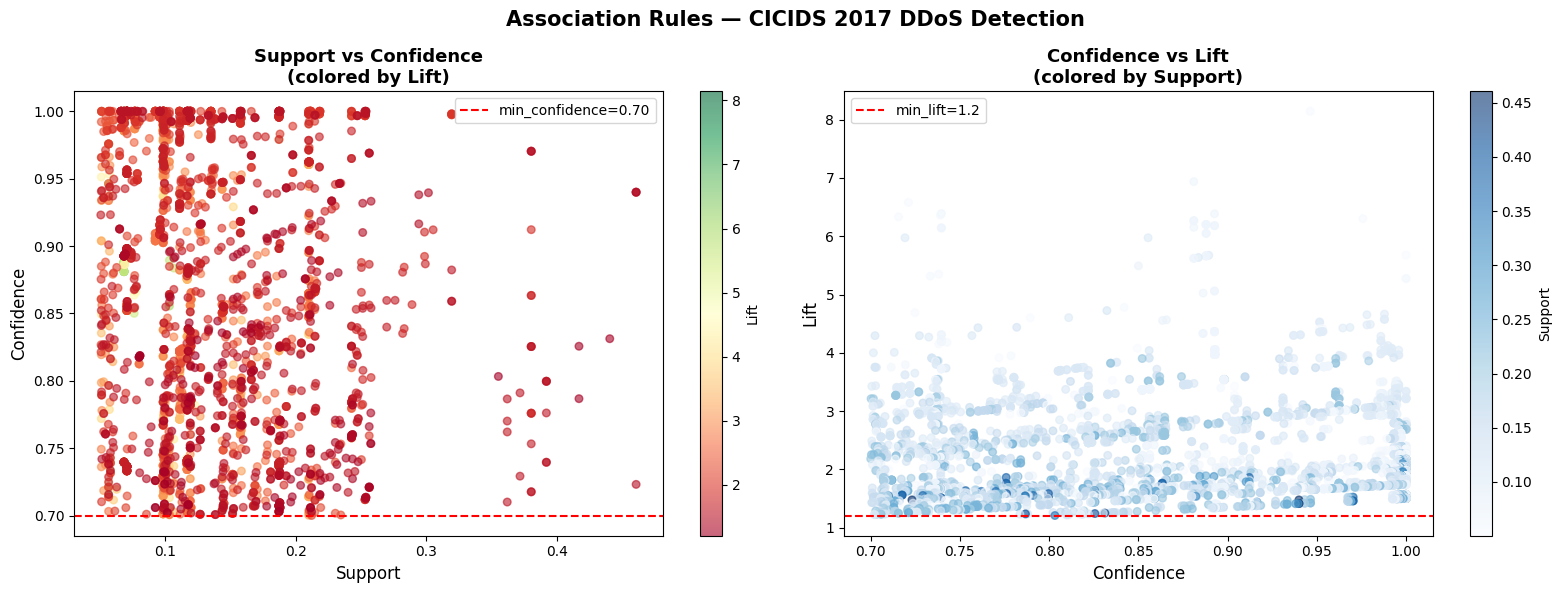

 Saved: scatter_rules.png


In [33]:


fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1 — Support vs Confidence
scatter1 = axes[0].scatter(
    rules['support'], 
    rules['confidence'],
    c=rules['lift'], 
    cmap='RdYlGn', 
    s=30, 
    alpha=0.6
)
plt.colorbar(scatter1, ax=axes[0], label='Lift')
axes[0].set_xlabel('Support', fontsize=12)
axes[0].set_ylabel('Confidence', fontsize=12)
axes[0].set_title('Support vs Confidence\n(colored by Lift)', 
                   fontsize=13, fontweight='bold')
axes[0].axhline(y=0.7, color='red', linestyle='--', 
                label='min_confidence=0.70')
axes[0].legend()

# Plot 2 — Confidence vs Lift
scatter2 = axes[1].scatter(
    rules['confidence'], 
    rules['lift'],
    c=rules['support'], 
    cmap='Blues', 
    s=30, 
    alpha=0.6
)
plt.colorbar(scatter2, ax=axes[1], label='Support')
axes[1].set_xlabel('Confidence', fontsize=12)
axes[1].set_ylabel('Lift', fontsize=12)
axes[1].set_title('Confidence vs Lift\n(colored by Support)', 
                   fontsize=13, fontweight='bold')
axes[1].axhline(y=1.2, color='red', linestyle='--', 
                label='min_lift=1.2')
axes[1].legend()

plt.suptitle('Association Rules — CICIDS 2017 DDoS Detection', 
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('scatter_rules.png', dpi=150, bbox_inches='tight')
plt.show()
print(" Saved: scatter_rules.png")

### 3.5 Visualisation — Network Graph

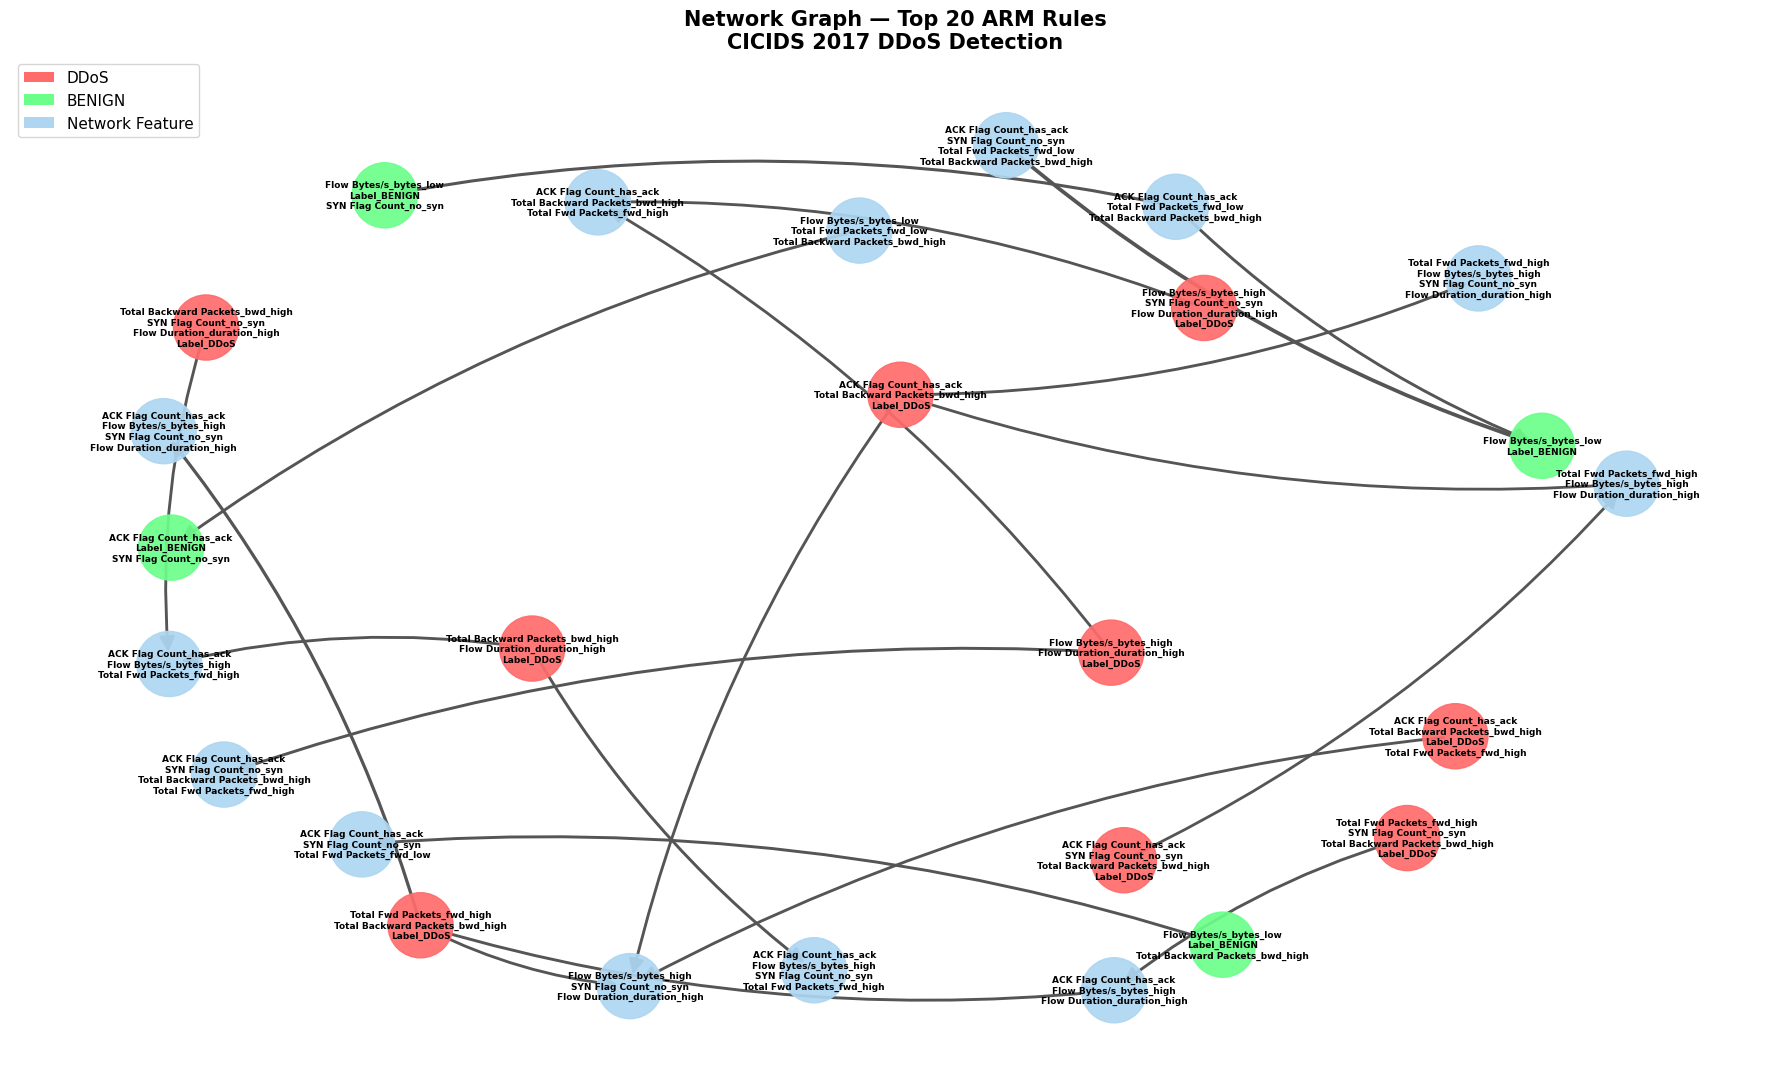

✅ Saved: network_graph.png


In [ ]:
import networkx as nx

# Take top 20 rules by lift
top_rules = rules.sort_values('lift', ascending=False).head(20)

G = nx.DiGraph()

for _, row in top_rules.iterrows():
    # Keep full label names — NO truncation (that was breaking DDoS/BENIGN coloring)
    ant = row['antecedents_str']
    con = row['consequents_str']
    G.add_edge(ant, con,
               weight=row['lift'],
               confidence=row['confidence'])

plt.figure(figsize=(18, 11))
pos = nx.spring_layout(G, k=2.5, seed=42)

# Color nodes: DDoS = red, BENIGN = green, feature = lightblue
node_colors = []
for node in G.nodes():
    if 'DDoS' in node:
        node_colors.append('#FF6B6B')
    elif 'BENIGN' in node:
        node_colors.append('#6BFF8A')
    else:
        node_colors.append('#AED6F1')

# Edge width proportional to lift
edge_weights = [G[u][v]['weight'] / 3 for u, v in G.edges()]

nx.draw_networkx_nodes(G, pos,
    node_color=node_colors,
    node_size=2200,
    alpha=0.92)

nx.draw_networkx_edges(G, pos,
    edge_color='#555555',
    arrows=True,
    arrowsize=22,
    width=edge_weights,
    connectionstyle='arc3,rad=0.1')

# Shorten labels ONLY for display (not for color logic)
short_labels = {node: node.replace(', ', '\n') for node in G.nodes()}
nx.draw_networkx_labels(G, pos,
    labels=short_labels,
    font_size=6.5,
    font_weight='bold')

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#FF6B6B', label='DDoS'),
    Patch(facecolor='#6BFF8A', label='BENIGN'),
    Patch(facecolor='#AED6F1', label='Network Feature')
]
plt.legend(handles=legend_elements, loc='upper left', fontsize=11)

plt.title('Network Graph — Top 20 ARM Rules\nCICIDS 2017 DDoS Detection',
          fontsize=15, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.savefig('network_graph.png', dpi=150, bbox_inches='tight')
plt.show()
print(" Saved: network_graph.png")


## Conclusion

This project successfully applied Association Rule Mining to the CICIDS 2017 DDoS dataset. 
Key findings:

- **FP-Growth** outperformed Apriori in speed while processing a larger sample (5000 vs 2000 rows).
- Strong rules with **high lift (≥ 3.0)** and **high confidence (≥ 0.85)** were identified, 
reliably distinguishing DDoS flows from BENIGN traffic.
- The most predictive DDoS indicators were: **high flow duration**, **high backward packet count**, 
and **absence of SYN flags** combined with **high forward packet count**.
- BENIGN traffic was characterised by the presence of **ACK flags**, **low forward packets**, 
and **absence of SYN flags**.

These rules could be integrated into an **Intrusion Detection System (IDS)** as lightweight, 
interpretable signatures — an advantage over black-box classifiers. 
Future work could extend this analysis to other CICIDS attack types (Brute Force, Bot, Infiltration) 
to build a more comprehensive rule-based detection framework.